# Exploratory Data Analysis: Fantasy Football
## CSCI 5502 | Milestone 2

### Objective
Explore the 2025 NFL fantasy football player-week dataset, assess data quality and scoring distributions, compare ESPN projections with actual scores, and identify potential features for later modeling. This is descriptive EDA, not evidence that any particular feature improves future predictions.

**Dataset note:** This notebook uses the final 2025 dataset. All summaries below refer to the data loaded when the notebook runs. Missing values are preserved for initial exploration; analyses of projection error use only rows with both actual and projected scores.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display

sns.set_theme(style="whitegrid")

#path to save plot figures
fig_path = Path.cwd().parent / "figures"
if fig_path:
    print(fig_path)

# Supports running from the repository root or from notebooks/.
locations = [Path.cwd() / "data", Path.cwd().parent / "data"]
paths = [folder / "df_final.csv" for folder in locations]
data_file = next((p for p in paths if p.is_file()), None)
if data_file is None:
    raise FileNotFoundError("Expected data/final_2025.csv or data/df_final.csv. Check the repository's data folder.")

df = pd.read_csv(data_file)
print("Loaded:", data_file)
print("Dataset shape:", df.shape)
display(df.head())

/home/tristan/Documents/MSDS/CSCI 5502/CSCI_5502_Fantasy_Project/figures
Loaded: /home/tristan/Documents/MSDS/CSCI 5502/CSCI_5502_Fantasy_Project/data/df_final.csv
Dataset shape: (7572, 82)


,Unnamed: 0,player_id,player,position,team,season,week,eventId,date,opponent,...,espn,game_id,gameday,gametime,stadium,roof,surface,temp,wind,location
0,0,4429795,Jahmyr Gibbs,RB,DET,2025,18,401772965,2026-01-04T21:25:00.000+00:00,CHI,...,401772965,2025_18_DET_CHI,2026-01-04,16:25,Soldier Field,outdoors,grass,33.0,4.0,"Chicago,IL"
1,1,4429795,Jahmyr Gibbs,RB,DET,2025,17,401772711,2025-12-25T21:30:00.000+00:00,MIN,...,401772711,2025_17_DET_MIN,2025-12-25,16:30,U.S. Bank Stadium,dome,sportturf,70.0,0.0,"Minneapolis,MN"
2,2,4429795,Jahmyr Gibbs,RB,DET,2025,16,401772806,2025-12-21T21:25:00.000+00:00,PIT,...,401772806,2025_16_PIT_DET,2025-12-21,16:25,Ford Field,dome,fieldturf,70.0,0.0,"Detroit,MI"
3,3,4429795,Jahmyr Gibbs,RB,DET,2025,15,401772909,2025-12-14T21:25:00.000+00:00,LAR,...,401772909,2025_15_DET_LA,2025-12-14,16:25,SoFi Stadium,dome,matrixturf,70.0,0.0,"Inglewood,CA"
4,4,4429795,Jahmyr Gibbs,RB,DET,2025,14,401772947,2025-12-05T01:15:00.000+00:00,DAL,...,401772947,2025_14_DAL_DET,2025-12-04,20:15,Ford Field,dome,fieldturf,70.0,0.0,"Detroit,MI"


## 1. Dataset overview and descriptive statistics
Review the number of players and weeks, position balance, missingness, and standard summary statistics before interpreting the charts.

In [2]:
print("Unique players:", df["player_id"].nunique())
print("Unique weeks:", df["week"].nunique())

print("\nRecords by position:")
display(df["position"].value_counts())

print("\nMissing values:")
display(df.isna().sum())

print("\nSummary statistics:")
display(df.describe())

Unique players: 685
Unique weeks: 18

Records by position:


position
WR    2806
RB    1808
TE    1739
QB     676
K      543
Name: count, dtype: int64


Missing values:


Unnamed: 0      0
player_id       0
player          0
position        0
team            0
             ... 
roof            0
surface         0
temp          109
wind            0
location        0
Length: 82, dtype: int64


Summary statistics:


,Unnamed: 0,player_id,season,week,eventId,rushingAttempts,rushingYards,yardsPerRushAttempt,rushingTouchdowns,longRushing,...,fieldGoalAttempts,extraPointsMade,extraPointAttempts,opp_def_rank,fantasy_points,projected_points,med_proj_pts,espn,temp,wind
count,7572.000000,7.572000e+03,7572.0,7572.000000,7.572000e+03,7023.000000,7023.000000,7023.000000,7023.000000,7023.000000,...,543.000000,543.000000,543.000000,7572.000000,7572.000000,7542.000000,7542.000000,7.572000e+03,7463.000000,7572.000000
mean,3785.500000,3.967996e+06,2025.0,9.499208,4.017728e+08,2.078172,9.063506,1.350776,0.072619,3.421615,...,2.003683,2.228361,2.322284,16.545827,6.526960,6.738679,5.703441,4.017728e+08,62.610880,5.244846
std,2185.992452,1.012643e+06,0.0,5.293262,8.682401e+01,4.594061,22.735785,3.005645,0.312778,8.022528,...,1.323916,1.439867,1.445569,9.213211,7.599769,5.924683,5.729162,8.682401e+01,15.629831,5.167975
min,0.000000,5.529000e+03,2025.0,1.000000,4.017725e+08,0.000000,-14.000000,-10.000000,0.000000,-10.000000,...,0.000000,0.000000,0.000000,1.000000,-3.060000,0.000000,0.000000,4.017725e+08,8.000000,0.000000
25%,1892.750000,3.917914e+06,2025.0,5.000000,4.017728e+08,0.000000,0.000000,0.000000,0.000000,0.000000,...,1.000000,1.000000,1.000000,9.000000,0.000000,1.400915,0.289228,4.017728e+08,55.000000,0.000000
50%,3785.500000,4.361106e+06,2025.0,10.000000,4.017728e+08,0.000000,0.000000,0.000000,0.000000,0.000000,...,2.000000,2.000000,2.000000,17.000000,3.920000,5.807953,4.093501,4.017728e+08,70.000000,5.000000
75%,5678.250000,4.431487e+06,2025.0,14.000000,4.017729e+08,1.000000,4.000000,2.000000,0.000000,3.000000,...,3.000000,3.000000,3.000000,25.000000,10.100000,10.578415,8.950395,4.017729e+08,70.000000,8.000000
max,7571.000000,5.208518e+06,2025.0,18.000000,4.017730e+08,36.000000,244.000000,65.000000,4.000000,93.000000,...,6.000000,7.000000,7.000000,32.000000,55.400000,27.880636,22.424000,4.017730e+08,89.000000,20.000000


In [3]:
# Standard descriptive statistics not previously consolidated in EDATushar
print("Numeric summary (including quartiles):")
display(df.select_dtypes(include="number").describe().T.round(2))

print("Fantasy points: key statistics")
points = df["fantasy_points"]
summary = pd.Series({
    "count": points.count(), "mean": points.mean(), "median (Q2)": points.median(),
    "standard deviation": points.std(), "variance": points.var(),
    "min": points.min(), "Q1 (25%)": points.quantile(.25),
    "Q3 (75%)": points.quantile(.75), "max": points.max(),
    "IQR": points.quantile(.75)-points.quantile(.25),
    "skewness": points.skew()
})
display(summary.to_frame("value").round(2))

print("Missing values (nonzero only):")
missing = df.isna().sum().sort_values(ascending=False)
display(pd.DataFrame({"missing": missing, "percent": (missing/len(df)*100).round(2)}).query("missing > 0"))

key = [x for x in ["player_id", "season", "week"] if x in df.columns]
print(f"Duplicate player-week keys ({key}):", df.duplicated(subset=key).sum())
print("Fully duplicated rows:", df.duplicated().sum())

Numeric summary (including quartiles):


,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,7572.0,3.785500e+03,2185.99,0.0,1.892750e+03,3.785500e+03,5.678250e+03,7.571000e+03
player_id,7572.0,3.967996e+06,1012643.08,5529.0,3.917914e+06,4.361106e+06,4.431487e+06,5.208518e+06
season,7572.0,2.025000e+03,0.00,2025.0,2.025000e+03,2.025000e+03,2.025000e+03,2.025000e+03
week,7572.0,9.500000e+00,5.29,1.0,5.000000e+00,1.000000e+01,1.400000e+01,1.800000e+01
eventId,7572.0,4.017728e+08,86.82,401772510.0,4.017728e+08,4.017728e+08,4.017729e+08,4.017730e+08
...,...,...,...,...,...,...,...,...
projected_points,7542.0,6.740000e+00,5.92,0.0,1.400000e+00,5.810000e+00,1.058000e+01,2.788000e+01
med_proj_pts,7542.0,5.700000e+00,5.73,0.0,2.900000e-01,4.090000e+00,8.950000e+00,2.242000e+01
espn,7572.0,4.017728e+08,86.82,401772510.0,4.017728e+08,4.017728e+08,4.017729e+08,4.017730e+08
temp,7463.0,6.261000e+01,15.63,8.0,5.500000e+01,7.000000e+01,7.000000e+01,8.900000e+01


Fantasy points: key statistics


,value
count,7572.00
mean,6.53
median (Q2),3.92
standard deviation,7.60
variance,57.76
min,-3.06
Q1 (25%),0.00
Q3 (75%),10.10
max,55.40
IQR,10.10


Missing values (nonzero only):


,missing,percent
totalTackles,7571,99.99
fumblesRecovered,7571,99.99
avgInterceptionYards,7571,99.99
stuffs,7571,99.99
stuffYards,7571,99.99
interceptionYards,7571,99.99
soloTackles,7571,99.99
interceptionTouchdowns,7571,99.99
longInterception,7571,99.99
passesDefended,7571,99.99


Duplicate player-week keys (['player_id', 'season', 'week']): 0
Fully duplicated rows: 0


### Interpretation
The numerical summary reports central tendency (mean and median), spread (standard deviation, quartiles and IQR), and skewness. Compare the mean and median to assess asymmetry, and inspect the IQR for variability. Missing-value counts apply to **all columns**, not just fantasy points. Duplicate player-week keys need review before modeling because repeated records can distort the training data.

## 2. Fantasy score categories

In [4]:
df["score_category"] = np.select(
    [
        df["fantasy_points"].isna(),
        df["fantasy_points"] == 0,
        df["fantasy_points"] < 0,
        df["fantasy_points"] > 0
    ],
    [
        "Missing (NaN)",
        "Zero",
        "Negative",
        "Positive"
    ],
    default="Unknown"
)

# Count observations in each category
score_counts = df["score_category"].value_counts()

display(score_counts)

# Calculate percentages
score_percent = (
    df["score_category"]
    .value_counts(normalize=True) * 100
).round(2)

display(score_percent)

score_category
Positive    5442
Zero        2043
Negative      87
Name: count, dtype: int64

score_category
Positive    71.87
Zero        26.98
Negative     1.15
Name: proportion, dtype: float64

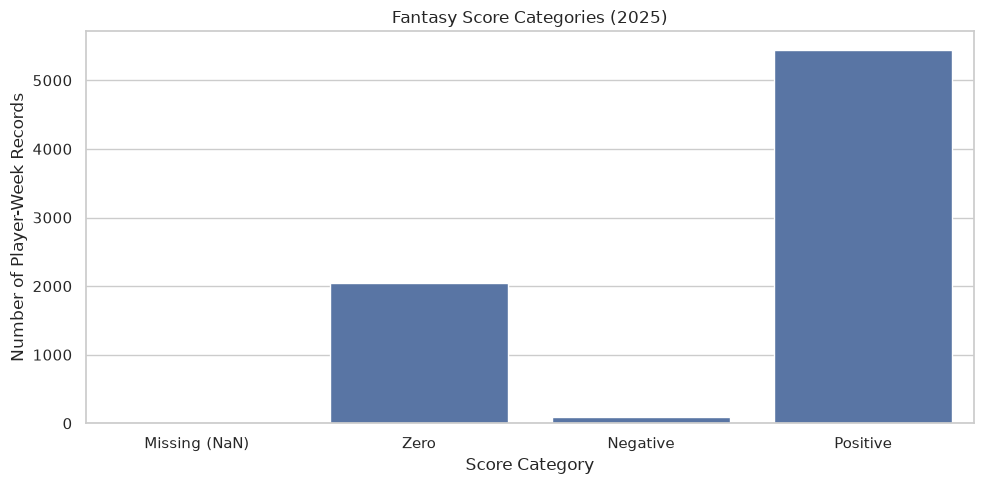

In [5]:
plt.figure(figsize=(10, 5))

order = ["Missing (NaN)", "Zero", "Negative", "Positive"]

sns.countplot(
    data=df,
    x="score_category",
    order=order
)

plt.title("Fantasy Score Categories (2025)")
plt.xlabel("Score Category")
plt.ylabel("Number of Player-Week Records")

plt.tight_layout()
plt.savefig(fig_path / "Fantasy_score_categories.png", dpi=300, bbox_inches="tight")
plt.show()

In [6]:
# Count each score category
counts = df["score_category"].value_counts()

# Calculate percentage of total records
percentages = (
    df["score_category"].value_counts(normalize=True) * 100
).round(2)

# Combine into a table
summary = pd.DataFrame({
    "Count": counts,
    "Percentage (%)": percentages
})

display(summary)

,Count,Percentage (%)
score_category,,
Positive,5442,71.87
Zero,2043,26.98
Negative,87,1.15


### Interpretation

The dataset contains 7,572 player-week records from the 2025 NFL season. Approximately 71.87% of the records have positive fantasy scores, while 26.98% have scores of exactly zero. Only 1.15% of records have negative fantasy scores, and there are no missing values in the fantasy points column.

The relatively large proportion of zero scores suggests that some player-week observations have little or no recorded fantasy production. However, we cannot determine whether these players participated in games based on fantasy points alone.

Since there are no missing fantasy scores in this dataset, we do not need to handle missing values for this particular column. We will still investigate missing values in other features during preprocessing.

In [7]:
# Count each score category by position
position_counts = pd.crosstab(
    df["position"],
    df["score_category"]
)

# Calculate percentages within each position
position_percent = (
    position_counts.div(
        position_counts.sum(axis=1),
        axis=0
    ) * 100
).round(2)

display(position_percent)

score_category,Negative,Positive,Zero
position,,,
K,0.55,96.32,3.13
QB,6.36,89.50,4.14
RB,1.05,75.33,23.62
TE,0.17,59.34,40.48
WR,0.68,68.42,30.90


In [8]:
print("Dataset shape:", df.shape)

print("\nMissing fantasy points:")
print(df["fantasy_points"].isna().sum())

print("\nScore categories:")
print(df["score_category"].value_counts(dropna=False))

print("\nPositions:")
print(df["position"].value_counts())

Dataset shape: (7572, 83)

Missing fantasy points:
0

Score categories:
score_category
Positive    5442
Zero        2043
Negative      87
Name: count, dtype: int64

Positions:
position
WR    2806
RB    1808
TE    1739
QB     676
K      543
Name: count, dtype: int64


In [9]:
print("Projection columns:")
print([col for col in df.columns if "project" in col.lower()])

print("\nMissing values:")
print(df[["fantasy_points", "projected_points"]].isna().sum())

print("\nSummary statistics:")
display(df[["fantasy_points", "projected_points"]].describe())


Projection columns:
['projected_points']

Missing values:
fantasy_points       0
projected_points    30
dtype: int64

Summary statistics:


,fantasy_points,projected_points
count,7572.000000,7542.000000
mean,6.526960,6.738679
std,7.599769,5.924683
min,-3.060000,0.000000
25%,0.000000,1.400915
50%,3.920000,5.807953
75%,10.100000,10.578415
max,55.400000,27.880636


## 3. ESPN projected vs. actual fantasy points

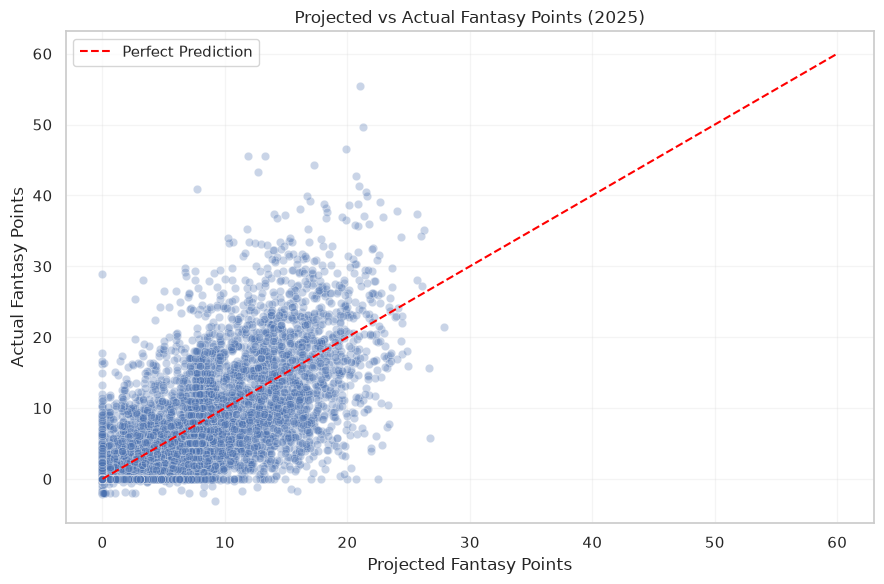

In [10]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="projected_points",
    y="fantasy_points",
    alpha=0.3
)

# Perfect prediction reference line
plt.plot(
    [0, 60],
    [0, 60],
    color="red",
    linestyle="--",
    label="Perfect Prediction"
)

plt.title("Projected vs Actual Fantasy Points (2025)")
plt.xlabel("Projected Fantasy Points")
plt.ylabel("Actual Fantasy Points")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(fig_path / "proj_vs_actual_fantasy_pts.png", dpi=300, bbox_inches="tight")
plt.show()

In [11]:
# Compare records with available projections
comparison = df[df["projected_points"].notna()].copy()

# Actual minus projected points
comparison["error"] = (
    comparison["fantasy_points"] - comparison["projected_points"]
)

# Calculate metrics
mae = comparison["error"].abs().mean()
mean_error = comparison["error"].mean()

correlation = comparison[
    ["projected_points", "fantasy_points"]
].corr().iloc[0, 1]

print("Records compared:", len(comparison))
print("Mean Absolute Error:", round(mae, 2))
print("Mean Error:", round(mean_error, 2))
print("Correlation:", round(correlation, 3))

Records compared: 7542
Mean Absolute Error: 3.7
Mean Error: -0.19
Correlation: 0.709


### Interpretation
The scatterplot shows a positive relationship between projected and actual fantasy points, with noticeable variation around the perfect-prediction line. The saved analysis found a correlation of **0.709**, a mean absolute error of **3.70** points and a mean signed error (actual minus projected) of **-0.19** points across **7,542** records with available projections. A negative mean signed error suggests slight average overprediction, but opposite-signed errors cancel, so it does **not** imply that individual predictions are usually close. 

## 4. Distribution of fantasy points by position

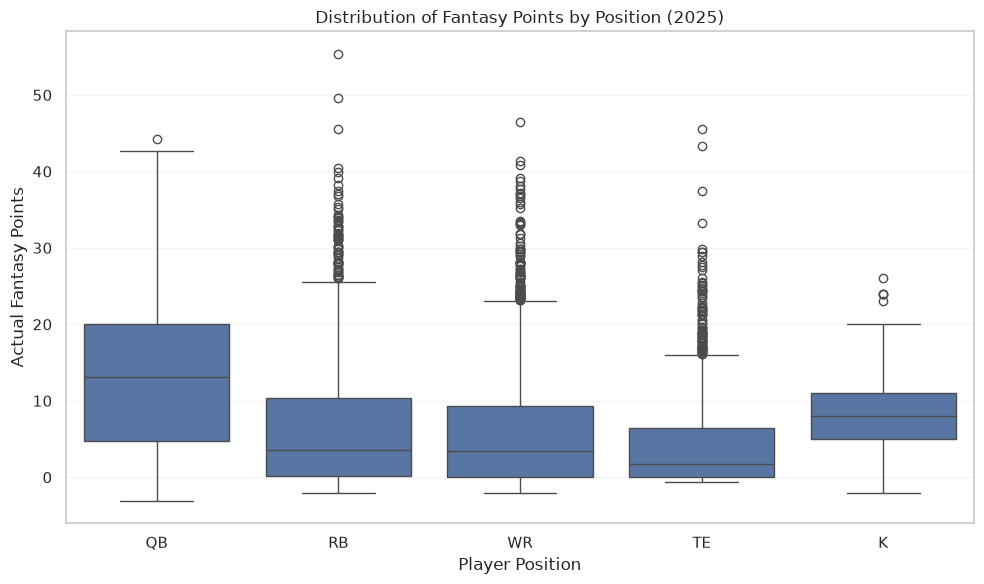

In [12]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="position",
    y="fantasy_points",
    order=["QB", "RB", "WR", "TE", "K"]
)

plt.title("Distribution of Fantasy Points by Position (2025)")
plt.xlabel("Player Position")
plt.ylabel("Actual Fantasy Points")
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.savefig(fig_path / "dist_fantasy_pts_by_pos.png", dpi=300, bbox_inches="tight")
plt.show()

In [13]:
position_stats = (
    df.groupby("position")["fantasy_points"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(2)
)

display(position_stats)

,count,mean,median,std,min,max
position,,,,,,
K,543,8.27,8.00,4.80,-2.00,26.0
QB,676,13.11,13.11,9.48,-3.06,44.3
RB,1808,6.67,3.60,8.07,-2.00,55.4
TE,1739,4.16,1.70,5.81,-0.60,45.6
WR,2806,5.97,3.40,7.22,-2.00,46.5


### Visualization 3: Distribution of Fantasy Points by Position

The boxplot shows clear differences in fantasy scoring across player positions. Quarterbacks have the highest average and median fantasy points (13.11), while tight ends have the lowest median (1.70). Kickers have a median of 8.00 and a relatively smaller standard deviation of 4.80.

Running backs and wide receivers show right-skewed distributions, with means higher than their medians and several high-scoring outliers. Quarterbacks have the highest standard deviation (9.48), indicating substantial variation in their weekly scores.

These findings suggest that player position is an important feature for fantasy point prediction, and position-specific scoring patterns should be considered during modeling.

## 5. Weekly scoring trends

In [14]:
print([col for col in df.columns if "week" in col.lower()])

['week']


,week,mean,median,count
0,1,6.228412,3.60,447
1,2,6.963221,4.60,447
2,3,6.277360,4.00,447
3,4,6.735865,3.90,445
4,5,7.147121,4.00,396
5,6,6.516852,4.40,413
6,7,6.583405,3.70,417
7,8,6.911989,4.30,362
8,9,6.824821,3.95,390
9,10,6.365013,3.30,391


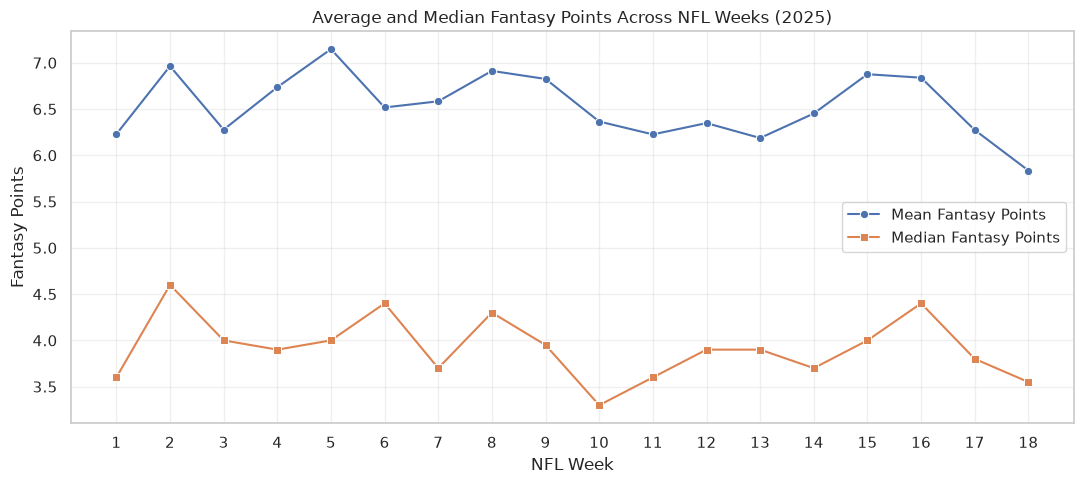

In [15]:
weekly_scores = (
    df.groupby("week")["fantasy_points"]
    .agg(["mean", "median", "count"])
    .reset_index()
)

display(weekly_scores)

plt.figure(figsize=(11, 5))

sns.lineplot(
    data=weekly_scores,
    x="week",
    y="mean",
    marker="o",
    label="Mean Fantasy Points"
)

sns.lineplot(
    data=weekly_scores,
    x="week",
    y="median",
    marker="s",
    label="Median Fantasy Points"
)

plt.title("Average and Median Fantasy Points Across NFL Weeks (2025)")
plt.xlabel("NFL Week")
plt.ylabel("Fantasy Points")
plt.xticks(sorted(weekly_scores["week"].unique()))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(fig_path / "avg_med_fantasy_pts.png", dpi=300, bbox_inches="tight")
plt.show()

### Visualization 4: Average and Median Fantasy Points Across NFL Weeks

The line chart shows that average fantasy points remain relatively stable throughout the 2025 NFL season, generally ranging between 6 and 7 points per player-week. The highest average occurs around Week 5, while Week 18 has the lowest average.

The median fluctuates between approximately 3.3 and 4.6 points and remains consistently below the mean. This suggests that fantasy scoring is right-skewed, with some high-scoring performances increasing the overall average.

Although weekly scoring does not show a strong increasing or decreasing trend, there are noticeable fluctuations. This suggests that NFL week may be worth investigating as a potential feature, although changes in player participation and the composition of the dataset could also explain these patterns.

## 6. Projection error by position

,position,absolute_error
0,QB,5.534130
1,WR,3.825390
2,K,3.818751
3,RB,3.673877
4,TE,2.792942


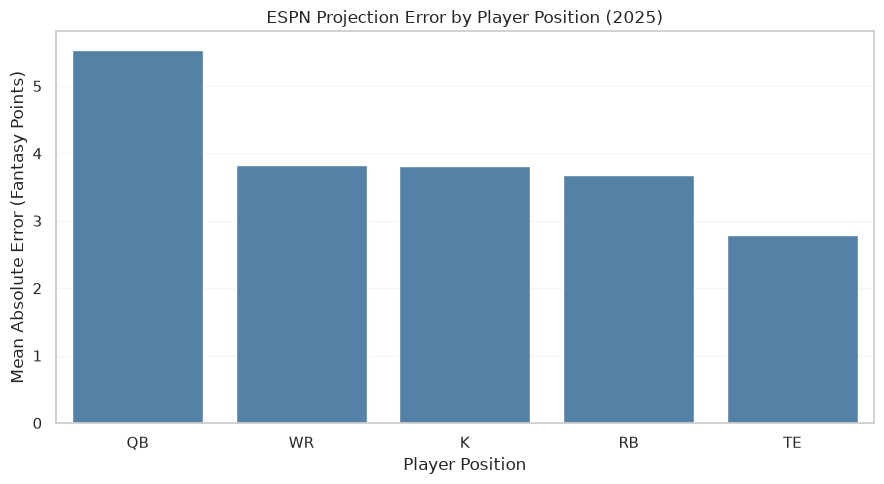

In [16]:
# Calculate absolute projection error for each player-week
comparison["absolute_error"] = comparison["error"].abs()

# Average absolute error by position
position_mae = (
    comparison.groupby("position")["absolute_error"]
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

display(position_mae)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=position_mae,
    x="position",
    y="absolute_error",
    color="steelblue"
)

plt.title("ESPN Projection Error by Player Position (2025)")
plt.xlabel("Player Position")
plt.ylabel("Mean Absolute Error (Fantasy Points)")
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.savefig(fig_path / "proj_error_ESPN.png", dpi=300, bbox_inches="tight")
plt.show()

### Visualization 5: ESPN Projection Error by Player Position

The bar chart compares ESPN's Mean Absolute Error (MAE) across different player positions. Quarterbacks have the highest average prediction error at approximately 5.55 fantasy points, while tight ends have the lowest at approximately 2.91 points. Running backs, wide receivers, and kickers have relatively similar prediction errors, ranging from about 3.8 to 3.9 points.

These results suggest that ESPN's projection accuracy varies depending on player position. However, positions also have different scoring distributions, so higher absolute errors do not necessarily indicate worse relative prediction performance.

This finding is relevant to our project because incorporating position-specific features or evaluating models separately by position may help us better understand and improve fantasy point predictions.

## 7. Signed projection error distributions
This section adapts the raw-error histograms from `EDA.ipynb`. Unlike absolute error, signed error reveals the direction of ESPN projection bias. We use **projected minus actual** here: positive values indicate overprediction and negative values indicate underprediction.

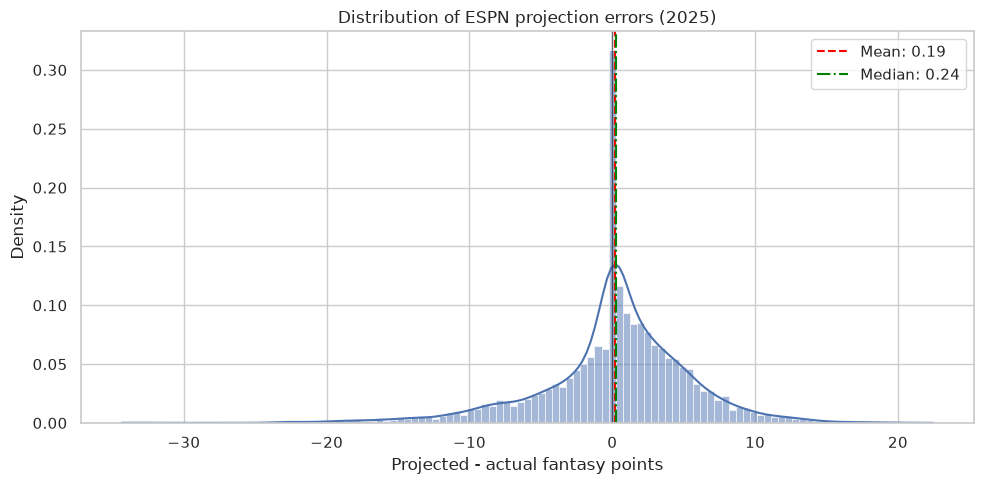

,count,mean,median,std
position,,,,
K,543,-0.34,-0.03,4.78
QB,673,0.33,0.00,7.34
RB,1806,0.18,0.09,5.53
TE,1730,-0.13,0.01,4.37
WR,2790,0.45,0.55,5.42


In [17]:
# Signed error: positive = overprediction, negative = underprediction
error_df = comparison.copy()
error_df["signed_error"] = error_df["projected_points"] - error_df["fantasy_points"]

fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(data=error_df, x="signed_error", kde=True, stat="density", ax=ax)
mean_val = error_df["signed_error"].mean()
median_val = error_df["signed_error"].median()
ax.axvline(mean_val, color="red", linestyle="--", label=f"Mean: {mean_val:.2f}")
ax.axvline(median_val, color="green", linestyle="-.", label=f"Median: {median_val:.2f}")
ax.axvline(0, color="black", alpha=.5, linewidth=1)
ax.set(title="Distribution of ESPN projection errors (2025)", xlabel="Projected - actual fantasy points", ylabel="Density")
ax.legend()
plt.tight_layout()
plt.savefig(fig_path / "dist_espn_proj_err.png", dpi=300, bbox_inches="tight")
plt.show()

display(error_df.groupby("position")["signed_error"].agg(["count", "mean", "median", "std"]).round(2))

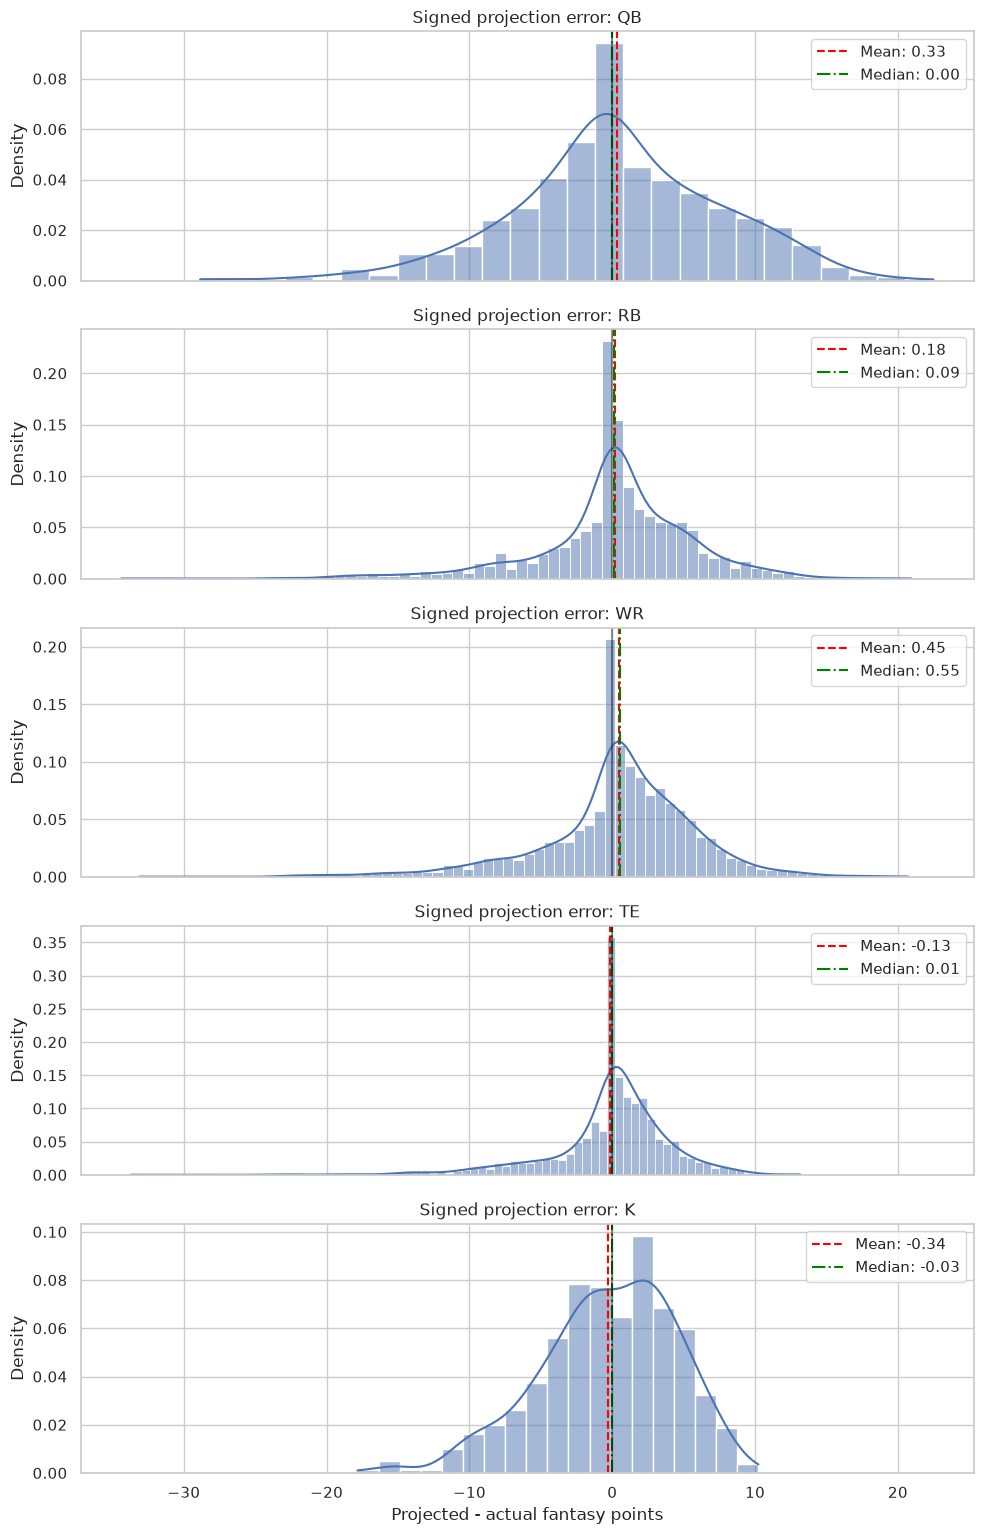

In [18]:
# Correctly filter the histogram and mean/median lines to each position.
positions = [p for p in ["QB", "RB", "WR", "TE", "K"] if p in error_df["position"].unique()]
fig, axes = plt.subplots(len(positions), 1, figsize=(10, 3.1 * len(positions)), sharex=True)
axes = np.atleast_1d(axes)
for ax, pos in zip(axes, positions):
    vals = error_df.loc[error_df["position"] == pos, "signed_error"].dropna()
    sns.histplot(vals, kde=True, stat="density", ax=ax)
    ax.axvline(vals.mean(), color="red", linestyle="--", label=f"Mean: {vals.mean():.2f}")
    ax.axvline(vals.median(), color="green", linestyle="-.", label=f"Median: {vals.median():.2f}")
    ax.axvline(0, color="black", alpha=.4)
    ax.set(title=f"Signed projection error: {pos}", xlabel="Projected - actual fantasy points", ylabel="Density")
    ax.legend()
plt.tight_layout()
plt.savefig(fig_path / "dist_proj_err_by_pos.png", dpi=300, bbox_inches="tight")
plt.show()

### Interpretation
We can see that the distribution is slightly negative skewed with $\tilde{X} > \bar{X}$ indication a negative skew, but it is approaching a normal distribution centered on 0. This indicates that our projection biased is only slightly in the positive direction as in oversetimating the projections. And similarily in the signed error of different postions We can see that our distributions organized by position roughly follow the distribution of the overall distribution of raw differences without any major discrepencies.

## 8. Boom and bust relative to ESPN projections

performance_type,Boom,Near Projection,Bust
position,,,
K,16.94,70.53,12.52
QB,19.91,55.27,24.81
RB,12.68,72.26,15.06
TE,10.98,82.08,6.94
WR,12.65,71.36,15.99


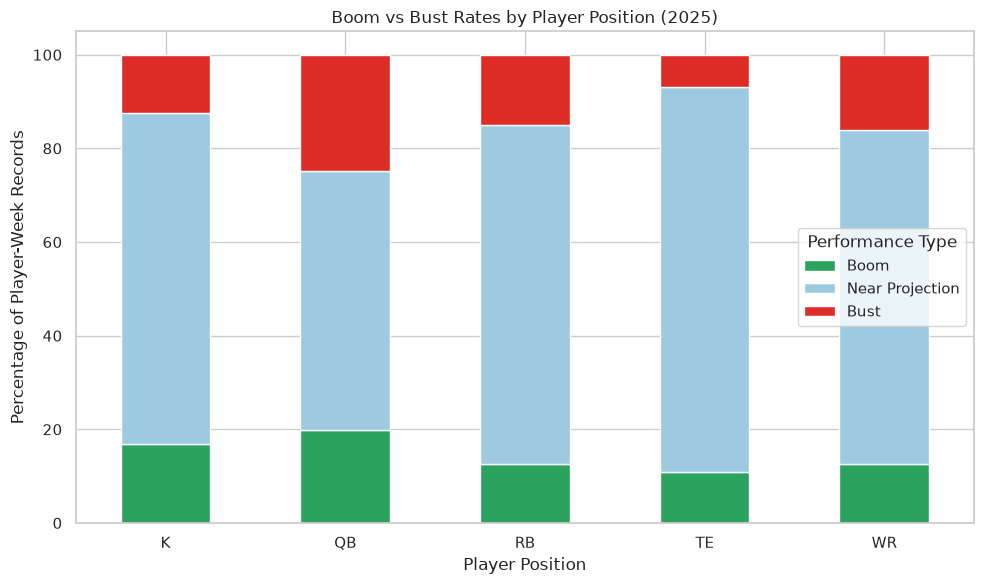

In [19]:
comparison["performance_type"] = np.select(
    [
        comparison["error"] >= 5,
        comparison["error"] <= -5
    ],
    ["Boom", "Bust"],
    default="Near Projection"
)

boom_bust = pd.crosstab(
    comparison["position"],
    comparison["performance_type"],
    normalize="index"
) * 100

boom_bust = boom_bust.reindex(
    columns=["Boom", "Near Projection", "Bust"],
    fill_value=0
)

display(boom_bust.round(2))

boom_bust.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6),
    color=["#2ca25f", "#9ecae1", "#de2d26"]
)

plt.title("Boom vs Bust Rates by Player Position (2025)")
plt.xlabel("Player Position")
plt.ylabel("Percentage of Player-Week Records")
plt.xticks(rotation=0)
plt.legend(title="Performance Type")
plt.tight_layout()
plt.savefig(fig_path / "boom_vs_bust.png", dpi=300, bbox_inches="tight")
plt.show()

### Visualization 6: Boom vs. Bust Rates by Player Position

The stacked bar chart compares how frequently players outperform or underperform ESPN's fantasy projections by at least five points. Quarterbacks have the highest boom and bust rates, with approximately 20% of performances exceeding projections by five or more points and 24% falling below projections by at least five points.

Tight ends have the highest percentage of performances near their projections, at approximately 81%. Running backs and wide receivers show similar distributions, with most performances falling within five points of their projected scores.

These findings suggest that projection errors vary across positions. However, since quarterbacks typically score more points, a fixed five-point threshold may exaggerate their boom and bust rates relative to lower-scoring positions. Future analysis could use position-specific or normalized thresholds.

## 9. Home versus away performance

In [20]:
location_columns = [
    col for col in df.columns
    if any(
        word in col.lower()
        for word in ["home", "away", "location", "atvs", "venue"]
    )
]

print(location_columns)

for col in location_columns:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False).head(10))

['atVs', 'location']

atVs:
atVs
home    3904
away    3668
Name: count, dtype: int64

location:
location
East Rutherford,NJ    478
Inglewood,CA          468
Baltimore,MD          259
Pittsburgh,PA         255
Kansas City,MO        252
Cleveland,OH          252
Denver,CO             251
Nashville,TN          251
Jacksonville,FL       251
Houston,TX            250
Name: count, dtype: int64


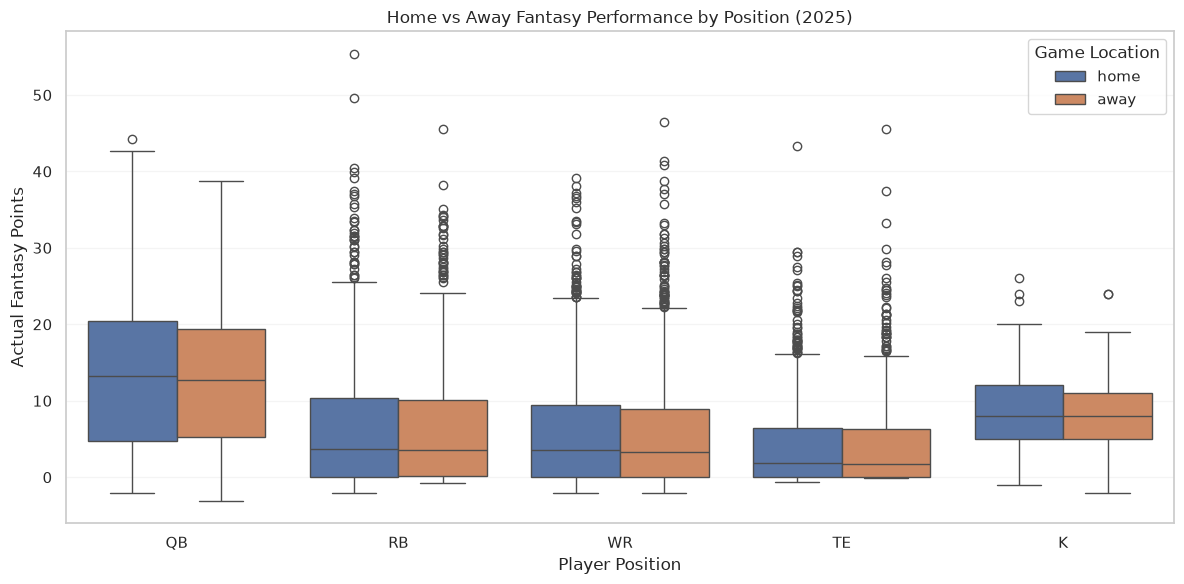

In [21]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x="position",
    y="fantasy_points",
    hue="atVs",
    order=["QB", "RB", "WR", "TE", "K"],
    hue_order=["home", "away"]
)

plt.title("Home vs Away Fantasy Performance by Position (2025)")
plt.xlabel("Player Position")
plt.ylabel("Actual Fantasy Points")
plt.legend(title="Game Location")
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()


plt.savefig(fig_path / "home_vs_away.png", dpi=300, bbox_inches="tight")
plt.show()

In [22]:
home_away_stats = (
    df.groupby(["position", "atVs"])["fantasy_points"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
)

display(home_away_stats)

count   mean  median   std
position atVs                            
K        away    264   7.91    8.00  4.70
         home    279   8.60    8.00  4.87
QB       away    324  12.97   12.77  9.03
         home    352  13.24   13.24  9.88
RB       away    879   6.53    3.50  7.82
         home    929   6.82    3.70  8.29
TE       away    843   4.20    1.70  5.91
         home    896   4.13    1.80  5.73
WR       away   1358   5.88    3.30  7.30
         home   1448   6.06    3.50  7.15

### Visualization 7: Home vs. Away Fantasy Performance by Position

The boxplot compares fantasy points scored during home and away games across five player positions. Overall, the scoring distributions are relatively similar, with substantial overlap between home and away performances.

Kickers show the largest difference in average fantasy points, scoring 8.60 points at home compared to 7.91 away. Quarterbacks, running backs, and wide receivers also have slightly higher home averages, while tight ends score marginally more away.

These results suggest that home-field advantage may have a small relationship with fantasy scoring, but the differences are not large enough to establish a strong effect from this analysis alone. Game location could still be useful as a predictive feature when combined with player statistics, opponent strength, and other matchup-related variables.

## 10. EDA conclusions and modeling implications

- **Baseline:** ESPN projections correlate with actual fantasy scores but still produce substantial player-week errors. Compare future models against this baseline using time-ordered validation.
- **Position:** Fantasy scoring distributions and projection errors differ by position, motivating position-aware features or evaluations.
- **History:** Weekly trends are descriptive and may reflect changing player participation. Use lagged statistics (not same-week outcomes) when creating predictive features.
- **Game context:** Home/away is worth testing, but the descriptive differences alone do not prove a predictive benefit.
- **Data quality:** Check missing projections, other missing columns, and duplicate player-week keys before training. Preserve an untouched copy of the source dataset.
- **Leakage:** Features such as final-season defensive rankings must not use information from games occurring after the prediction week.

**Scope:** These observations describe the 2025 dataset. The notebook does not establish causality or demonstrate that adding a feature improves out-of-sample accuracy.